# Unsupervised Learning in TensorFlow: Autoencoder + K-Means

**Goal:** Discover groups in unlabeled, six-feature synthetic data by training a TensorFlow autoencoder and then applying K-Means to its learned two-dimensional representation.

This notebook runs **top to bottom in Google Colab**. No CSV upload, Google Drive mount, GPU, or other dataset is required. Choose **Runtime → Run all**.

**Libraries:** TensorFlow/Keras (representation learning), scikit-learn (data generation, scaling, clustering, silhouette score), NumPy (arrays), Matplotlib (charts).

> **Note:** K-Means is run with scikit-learn, not TensorFlow. TensorFlow trains the unsupervised feature extractor. The cluster IDs are discovered, not ground-truth labels.

## 1. Import the libraries and set a random seed

Colab typically includes these libraries. If one is missing, run `!pip install tensorflow scikit-learn matplotlib` in a new cell and restart the runtime if prompted.

A fixed seed makes the example easier to reproduce, although results can still vary across devices or library versions.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
N_SAMPLES = 900
N_FEATURES = 6
N_CLUSTERS = 3       # We set the number of groups for this educational example.
LATENT_DIM = 2       # Two features make it easy to visualize the learned space.

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)
print('Runtime ready. GPU is optional.')

TensorFlow version: 2.21.0
Runtime ready. GPU is optional.


## 2. Generate **unlabeled** example data

`make_blobs()` produces six numerical measurements per observation. It also generates class IDs internally, but **we discard them** so neither the autoencoder nor K-Means sees any true labels.

In a real project, this step would usually be replaced by `pd.read_csv()` and selection of suitable numerical feature columns.

In [2]:
# Each row is one data point; each column is a numerical feature.
X, _ignored_ground_truth = make_blobs(
    n_samples=N_SAMPLES,
    n_features=N_FEATURES,
    centers=N_CLUSTERS,
    cluster_std=1.5,
    random_state=SEED,
)
X = X.astype(np.float32)  # float32 is efficient and compatible with TensorFlow.

print('Dataset dimensions (samples, features):', X.shape)
print('Example observation:', X[0])

Dataset dimensions (samples, features): (900, 6)
Example observation: [ 7.4217944  -7.0046406  -3.0873556  -5.476149   -4.7861276  -0.42194924]


## 3. Preprocess the features using StandardScaler

1. Split into **training** and **validation** rows before calculating any scaling statistics.
2. Fit `StandardScaler` **only on the training subset**. This prevents validation-set information from influencing preprocessing.
3. Transform both subsets and the full data with the training statistics.

Standardization maps each feature to approximately zero mean and unit standard deviation *on the training set*. It reduces the tendency of large-scale measurements to dominate reconstruction loss and Euclidean distance.

In [3]:
X_train, X_val = train_test_split(
    X, test_size=0.20, random_state=SEED
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_all_scaled = scaler.transform(X).astype(np.float32)

print('Training observations:', X_train_scaled.shape[0])
print('Validation observations:', X_val_scaled.shape[0])
print('Training feature means (approximately 0):', X_train_scaled.mean(axis=0).round(3))
print('Training feature standard deviations (approximately 1):', X_train_scaled.std(axis=0).round(3))

Training observations: 720
Validation observations: 180
Training feature means (approximately 0): [-0. -0.  0. -0.  0. -0.]
Training feature standard deviations (approximately 1): [1. 1. 1. 1. 1. 1.]


## 4. Build a TensorFlow autoencoder

An autoencoder is trained to reconstruct its input. It consists of:

- **Encoder:** compresses six features down to a small *latent representation* of two values.
- **Decoder:** tries to reconstruct the six original standardized values from the two learned features.

The model minimizes **mean squared reconstruction error**; it does not use labels. Low reconstruction error means the model preserves information, but it does not automatically guarantee good or meaningful clusters.

In [4]:
# Functional API lets us extract the encoder as a separate trained model.
inputs = tf.keras.Input(shape=(N_FEATURES,), name='six_input_features')

# Encoder: 6 -> 16 -> 8 -> 2 dimensions.
x = tf.keras.layers.Dense(16, activation='relu', name='encoder_hidden_1')(inputs)
x = tf.keras.layers.Dense(8, activation='relu', name='encoder_hidden_2')(x)
latent = tf.keras.layers.Dense(LATENT_DIM, name='two_dimensional_embedding')(x)

# Decoder: 2 -> 8 -> 16 -> 6 dimensions.
x = tf.keras.layers.Dense(8, activation='relu', name='decoder_hidden_1')(latent)
x = tf.keras.layers.Dense(16, activation='relu', name='decoder_hidden_2')(x)
reconstructed = tf.keras.layers.Dense(N_FEATURES, name='reconstruction')(x)

# Both models share the exact same trained encoder layers.
autoencoder = tf.keras.Model(inputs, reconstructed, name='autoencoder')
encoder = tf.keras.Model(inputs, latent, name='encoder')

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
)

autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ six_input_features (InputLayer) │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden_1 (Dense)        │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden_2 (Dense)        │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ two_dimensional_embedding       │ (None, 2)              │            18 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden_1 (Dense)        │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_hidden_2 (Dense)        │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 536 (2.09 KB)

 Trainable params: 536 (2.09 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model using input reconstruction

Notice the arguments `X_train_scaled, X_train_scaled` to `.fit()`:

- First array: input data.
- Second array: **the same input data**, used as the desired reconstruction.

There are no target class labels. `EarlyStopping` restores the weights from the epoch with the best observed validation loss to reduce unnecessary training and overfitting.

In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True,
)

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,  # Reconstruction target = the original input.
    validation_data=(X_val_scaled, X_val_scaled),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0,          # Reduce console output in Colab.
)

# Evaluate the restored model, not only the last recorded epoch's history.
val_mse = autoencoder.evaluate(X_val_scaled, X_val_scaled, verbose=0)
print('Epochs completed:', len(history.history['loss']))
print(f'Validation reconstruction MSE (restored best weights): {val_mse:.4f}')

Epochs completed: 100
Validation reconstruction MSE (restored best weights): 0.0491


## 6. Extract features and discover clusters

The encoder converts each six-feature observation to a two-feature learned embedding. We then fit K-Means on that embedding using **Euclidean distance**.

- K-Means cluster IDs (0, 1, 2) are arbitrary identifiers, not grades or predictions of known classes.
- The silhouette score checks how separated the predicted groups appear in the learned two-dimensional space. Higher is generally better, but it does **not** establish scientific or business validity of the groups.
- Here we choose `n_clusters=3` up front to keep the demonstration predictable; a real project should compare multiple values.

In [6]:
# Compress all observations using the trained TensorFlow encoder.
latent_features = encoder.predict(X_all_scaled, verbose=0)

# Fit a conventional unsupervised clustering algorithm to learned features.
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
cluster_labels = kmeans.fit_predict(latent_features)

silhouette = silhouette_score(latent_features, cluster_labels)
print('Learned embedding shape:', latent_features.shape)
print(f'Silhouette score (learned feature space): {silhouette:.3f}')

for cluster_id, count in enumerate(np.bincount(cluster_labels, minlength=N_CLUSTERS)):
    print(f'Cluster {cluster_id}: {count} observations')

Learned embedding shape: (900, 2)
Silhouette score (learned feature space): 0.808
Cluster 0: 300 observations
Cluster 1: 300 observations
Cluster 2: 300 observations


## 7. Visualize the training process and clustering result

The first panel shows reconstruction loss over epochs. The middle panel displays only the **first two original scaled features** and colors them using the discovered clusters; it is not a two-dimensional representation of all six features. The right panel shows the **learned two-dimensional latent space**, including K-Means centroids.

Charts display **inline in Colab** automatically. The script also saves one PNG to the runtime's `outputs` folder.

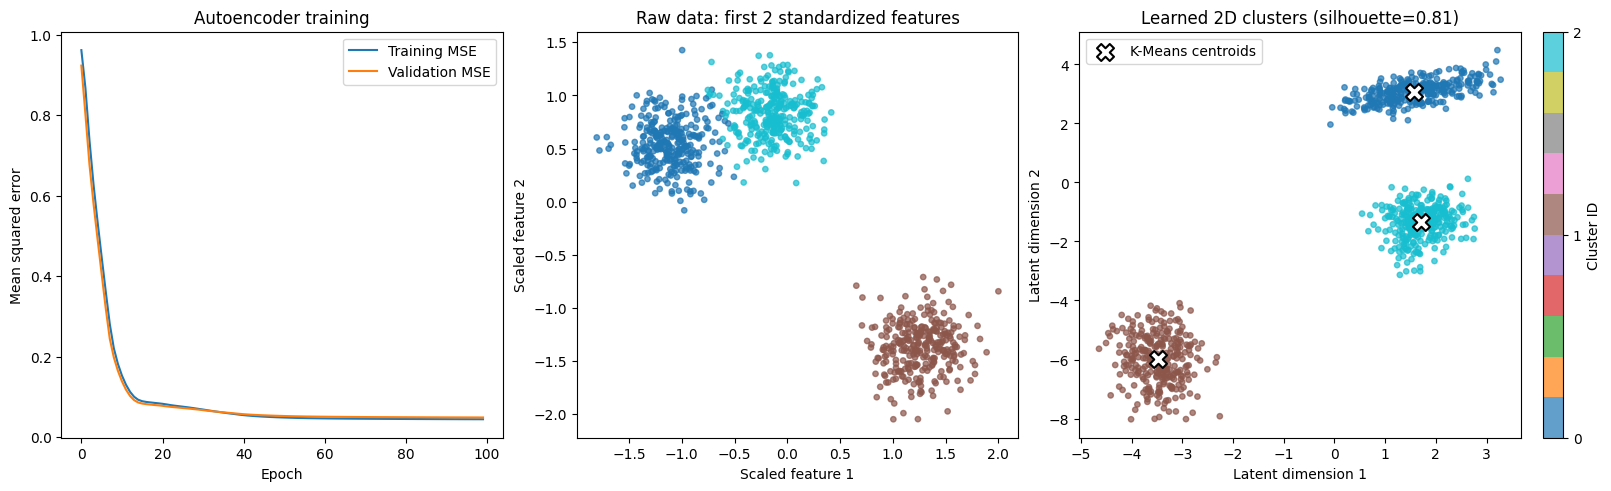

Saved plot to: /content/outputs/tensorflow_autoencoder_clusters.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

# Plot 1: Did the model learn to reconstruct the examples?
axes[0].plot(history.history['loss'], label='Training MSE')
axes[0].plot(history.history['val_loss'], label='Validation MSE')
axes[0].set(title='Autoencoder training', xlabel='Epoch', ylabel='Mean squared error')
axes[0].legend()

# Plot 2: Only the first two (out of six) standardized raw features.
axes[1].scatter(
    X_all_scaled[:, 0], X_all_scaled[:, 1],
    c=cluster_labels, cmap='tab10', s=15, alpha=0.7,
)
axes[1].set(
    title='Raw data: first 2 standardized features',
    xlabel='Scaled feature 1', ylabel='Scaled feature 2',
)

# Plot 3: All six features compressed into a 2D learned representation.
points = axes[2].scatter(
    latent_features[:, 0], latent_features[:, 1],
    c=cluster_labels, cmap='tab10', s=15, alpha=0.7,
)
axes[2].scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    marker='X', s=150, edgecolors='black', linewidths=1.5,
    facecolors='white', label='K-Means centroids',
)
axes[2].set(
    title=f'Learned 2D clusters (silhouette={silhouette:.2f})',
    xlabel='Latent dimension 1', ylabel='Latent dimension 2',
)
axes[2].legend()
fig.colorbar(points, ax=axes[2], ticks=range(N_CLUSTERS), label='Cluster ID')

# Colab's current working directory is usually /content, so the output will
# be saved under /content/outputs when running in a fresh Colab runtime.
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
plot_path = output_dir / 'tensorflow_autoencoder_clusters.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()  # Colab renders the plot inside the cell.
print('Saved plot to:', plot_path.resolve())

## 8. Optional: download the PNG from Google Colab

Uncomment these two lines in a new code cell if you want a local copy of the visualization. This step is optional and only works inside Colab:

```python
from google.colab import files
files.download('outputs/tensorflow_autoencoder_clusters.png')
```

### What you learned

- **StandardScaler** makes feature magnitudes comparable.
- A **TensorFlow autoencoder** can learn features without class labels.
- **K-Means** can group observations using learned features.
- A **silhouette score** describes cluster geometry, not true group identity.
- Matplotlib helps visualize model convergence and cluster separation.

For real data, replace the synthetic dataset cell with your CSV and carefully select numerical features. This notebook is designed for demonstration, not clinical or high-stakes decisions.